# Space Missions: failure rate and launch locations
A mission counts as a failure if its status is anything other than `Success` (Failure, Partial Failure, Prelaunch Failure).

In [ ]:
import pandas as pd

# The file uses an older text encoding (latin-1), so it must be stated explicitly
df = pd.read_csv("space_missions.csv", encoding="latin-1")
print(df.shape)
df.head()

(4630, 9)


,Company,Location,Date,Time,Rocket,Mission,RocketStatus,Price,MissionStatus
0,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,NaN,Success
1,RVSN USSR,"Site 1/5, Baikonur Cosmodrome, Kazakhstan",1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,NaN,Success
2,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,NaN,Failure
3,AMBA,"LC-26A, Cape Canaveral AFS, Florida, USA",1958-02-01,03:48:00,Juno I,Explorer 1,Retired,NaN,Success
4,US Navy,"LC-18A, Cape Canaveral AFS, Florida, USA",1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,NaN,Failure


In [ ]:
df["Failed"] = df["MissionStatus"] != "Success"

print(df["MissionStatus"].value_counts())
print(f"\nOverall failure rate: {df['Failed'].mean():.2%} ({df['Failed'].sum()} of {len(df)} missions)")

MissionStatus
Success              4162
Failure               357
Partial Failure       107
Prelaunch Failure       4
Name: count, dtype: int64

Overall failure rate: 10.11% (468 of 4630 missions)


In [ ]:
# Location format: "Pad, Site, (Region,) Country"
parts = df["Location"].str.split(",")
df["Country"] = parts.str[-1].str.strip()
# Cleanup: some rows end with a state, island or facility name instead of the country
df["Country"] = df["Country"].replace({
    "New Mexico": "USA",                        # Spaceport America
    "Pacific Missile Range Facility": "USA",    # Kauai, Hawaii
    "Gran Canaria": "Spain",                    # Gando air base, Canary Islands
    "Shahrud Missile Test Site": "Iran",
})

# Site = the launch facility, ignoring the individual pad, so every row is compared at the same level.
# Usual layout is "Pad, Facility, [Region,] Country" -> the facility is the 2nd piece.
# Exceptions: 2-piece rows have no pad (facility is the 1st piece), and two rows name the facility last.
FACILITY_LAST = {"Pacific Missile Range Facility", "Shahrud Missile Test Site"}

def get_facility(pieces):
    pieces = [x.strip() for x in pieces]
    if pieces[-1] in FACILITY_LAST:
        return pieces[-1]
    return pieces[1] if len(pieces) >= 3 else pieces[0]

df["Site"] = parts.apply(get_facility)

# Merge names that refer to the same place: 2020 Space Force renames (AFS->SFS, AFB->SFB)
# and a text-encoding glitch that splits "Mahia Peninsula" into two spellings.
df["Site"] = df["Site"].replace({
    "Cape Canaveral AFS": "Cape Canaveral", "Cape Canaveral SFS": "Cape Canaveral",
    "Vandenberg AFB": "Vandenberg", "Vandenberg SFB": "Vandenberg",
})
df["Site"] = df["Site"].str.replace(r"^M.{1,3}hia Peninsula$", "Mahia Peninsula", regex=True)

def failure_table(col, top=10):
    t = df.groupby(col)["Failed"].agg(Launches="size", Failures="sum")
    t["Failure %"] = (t["Failures"] / t["Launches"] * 100).round(1)
    t["Share of all failures %"] = (t["Failures"] / df["Failed"].sum() * 100).round(1)
    return t.sort_values("Failures", ascending=False).head(top)

failure_table("Country", 12)

,Launches,Failures,Failure %,Share of all failures %
Country,,,,
USA,1472,174,11.8,37.2
Kazakhstan,719,94,13.1,20.1
Russia,1416,93,6.6,19.9
China,365,30,8.2,6.4
France,318,19,6.0,4.1
India,82,14,17.1,3.0
Japan,130,13,10.0,2.8
Iran,17,10,58.8,2.1
North Korea,5,3,60.0,0.6


### Failed missions by launch country

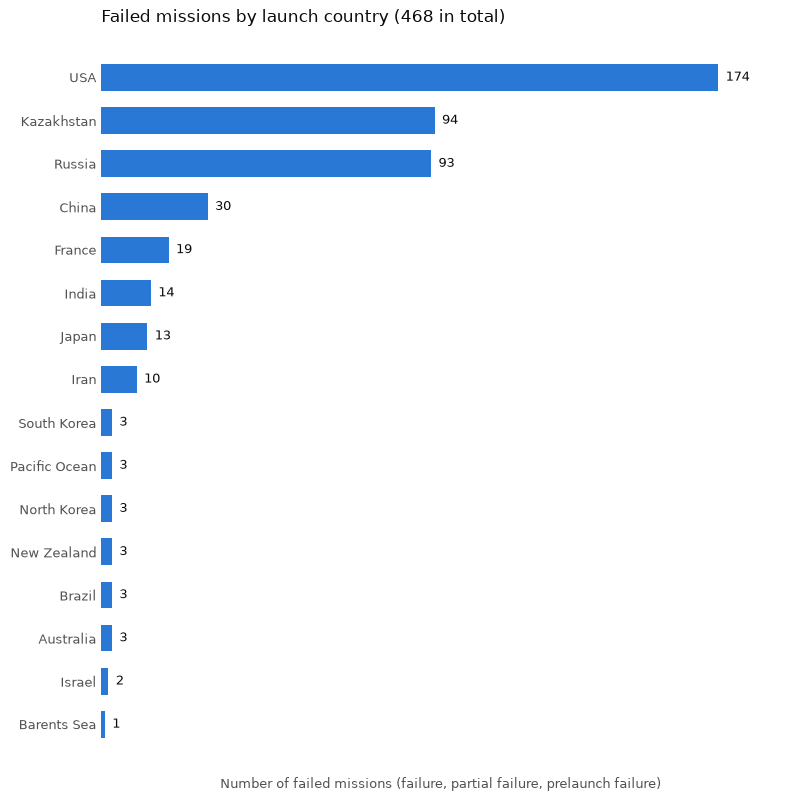

In [ ]:
import matplotlib.pyplot as plt

# Number of failed missions per country (only countries with at least one failure), largest at the top
by_country = df.groupby("Country")["Failed"].sum()
by_country = by_country[by_country > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 0.42 * len(by_country) + 1.4))
ax.barh(by_country.index, by_country.values, color="#2a78d6", height=0.62)

for y, v in enumerate(by_country.values):
    ax.text(v + by_country.max() * 0.012, y, int(v), va="center", fontsize=9, color="#0b0b0b")

ax.set_title(f"Failed missions by launch country ({int(by_country.sum())} in total)", loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Number of failed missions (failure, partial failure, prelaunch failure)", color="#52514e", fontsize=9)
ax.tick_params(axis="both", length=0, colors="#52514e")
ax.tick_params(axis="y", labelsize=9)
ax.set_xticks([])
for side in ("top", "right", "bottom", "left"):
    ax.spines[side].set_visible(False)
ax.set_xlim(0, by_country.max() * 1.1)
plt.tight_layout()
plt.show()

### Failure rate by launch country
Grey bars have fewer than 20 launches, so their rate can swing a lot on a single mission. Read them with caution.

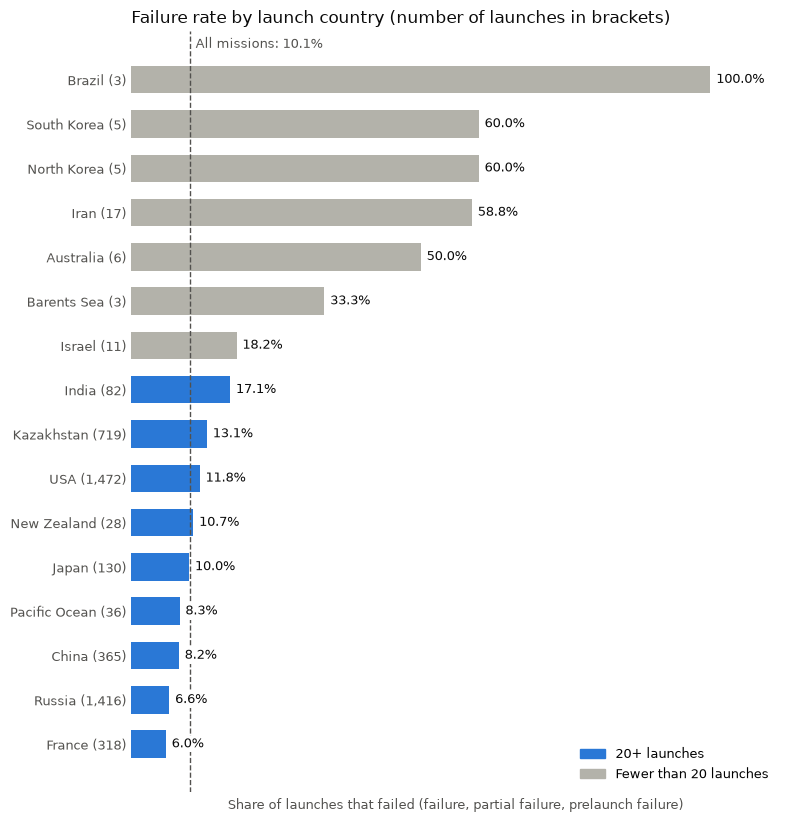

In [ ]:
from matplotlib.patches import Patch

MIN_LAUNCHES = 20  # below this, a rate is too unstable to compare

g = df.groupby("Country")["Failed"].agg(Launches="size", Failures="sum")
g = g[g["Failures"] > 0]
g["Rate"] = g["Failures"] / g["Launches"] * 100
g = g.sort_values("Rate")
overall = df["Failed"].mean() * 100

colors = ["#2a78d6" if n >= MIN_LAUNCHES else "#b3b2aa" for n in g["Launches"]]
labels = [f"{c} ({n:,})" for c, n in zip(g.index, g["Launches"])]

fig, ax = plt.subplots(figsize=(8, 0.42 * len(g) + 1.6))
ax.barh(labels, g["Rate"], color=colors, height=0.62)

for y, v in enumerate(g["Rate"]):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9, color="#0b0b0b", zorder=3,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

ax.axvline(overall, color="#52514e", linestyle="--", linewidth=1, zorder=2)
ax.text(overall + 1, len(g) - 0.35, f"All missions: {overall:.1f}%", fontsize=9, color="#52514e", va="bottom")

ax.set_title("Failure rate by launch country (number of launches in brackets)", loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Share of launches that failed (failure, partial failure, prelaunch failure)", color="#52514e", fontsize=9)
ax.legend(handles=[Patch(color="#2a78d6", label=f"{MIN_LAUNCHES}+ launches"),
                   Patch(color="#b3b2aa", label=f"Fewer than {MIN_LAUNCHES} launches")],
          loc="lower right", frameon=False, fontsize=9)
ax.tick_params(axis="both", length=0, colors="#52514e")
ax.tick_params(axis="y", labelsize=9)
ax.set_xticks([])
for side in ("top", "right", "bottom", "left"):
    ax.spines[side].set_visible(False)
ax.set_xlim(0, max(g["Rate"].max() * 1.12, 100))
plt.tight_layout()
plt.show()

### Failure rate by decade
n = number of launches. \* Partial decades: the 1950s only cover Oct 1957 to 1959, and the 2020s only run to July 2022.

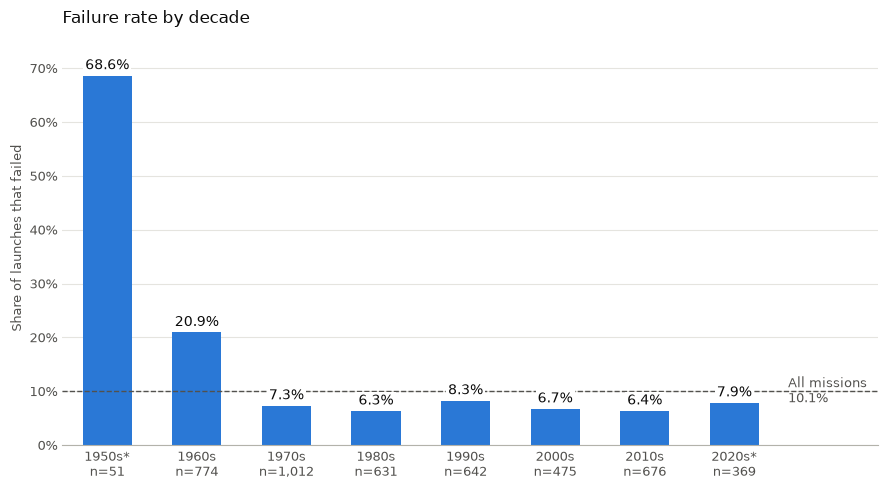

In [ ]:
df["Decade"] = (df["Date"].str[:4].astype(int) // 10 * 10)

d = df.groupby("Decade")["Failed"].agg(Launches="size", Failures="sum")
d["Rate"] = d["Failures"] / d["Launches"] * 100
overall = df["Failed"].mean() * 100

partial = {1950, 2020}  # incomplete decades, marked with *
labels = [f"{y}s{'*' if y in partial else ''}\nn={n:,}" for y, n in zip(d.index, d["Launches"])]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(labels, d["Rate"], color="#2a78d6", width=0.55)

for x, v in enumerate(d["Rate"]):
    ax.text(x, v + 1.2, f"{v:.1f}%", ha="center", fontsize=10, color="#0b0b0b", zorder=3,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

ax.axhline(overall, color="#52514e", linestyle="--", linewidth=1, zorder=1)
ax.text(len(d) - 0.4, overall, f"All missions\n{overall:.1f}%", ha="left", va="center", fontsize=9, color="#52514e")
ax.set_xlim(-0.5, len(d) + 0.6)

ax.set_title("Failure rate by decade", loc="left", fontsize=12, color="#0b0b0b")
ax.set_ylabel("Share of launches that failed", color="#52514e", fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylim(0, d["Rate"].max() * 1.12)
ax.tick_params(axis="both", length=0, colors="#52514e", labelsize=9)
ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#b3b2aa")
plt.tight_layout()
plt.show()

In [ ]:
failure_table("Site", 10)

,Launches,Failures,Failure %,Share of all failures %
Site,,,,
Baikonur Cosmodrome,719,94,13.1,20.1
Cape Canaveral,706,83,11.8,17.7
Plesetsk Cosmodrome,1278,76,5.9,16.2
Vandenberg,457,57,12.5,12.2
Guiana Space Centre,314,18,5.7,3.8
Kapustin Yar,112,16,14.3,3.4
Jiuquan Satellite Launch Center,144,14,9.7,3.0
Satish Dhawan Space Centre,82,14,17.1,3.0
Semnan Space Center,14,10,71.4,2.1


**Cleanup applied:** 8 rows end with a state, island or facility instead of a country. Recoded: `New Mexico` (4) and `Pacific Missile Range Facility` (1) to `USA`; `Gran Canaria` (2) to `Spain`; `Shahrud Missile Test Site` (1) to `Iran`. **Site** is the launch facility (e.g. all Cape Canaveral pads together, all Baikonur pads together), so sites are compared at one consistent level. Renamed bases (Cape Canaveral AFS/SFS, Vandenberg AFB/SFB) and the two spellings of Mahia Peninsula are merged. Sea launches (Pacific Ocean, Barents Sea, Yellow Sea) are kept as their own category. The CSV itself is unchanged.